In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import joblib

from pathlib import Path

from sklearn.model_selection import (
    StratifiedKFold,
    RandomizedSearchCV,
    cross_val_predict
)

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

c:\Users\yashr\OneDrive\Documents\AI CUSTOMER PREDICTION CHURN\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All libraries imported successfully!


Load your trained model and datasets
Load saved files

In [2]:
project = Path.cwd().parent

data_dir = project / "Data-processed"
models_dir = project / "models"

X_train = pd.read_csv(data_dir / "X_train.csv")
X_test = pd.read_csv(data_dir / "X_test.csv")

y_train = pd.read_csv(
    data_dir / "y_train.csv"
).iloc[:, 0]

y_test = pd.read_csv(
    data_dir / "y_test.csv"
).iloc[:, 0]

best_pipeline = joblib.load(
    models_dir / "best_churn_model.pkl"
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Loaded classifier:",
      type(best_pipeline.named_steps["classifier"]).__name__)

Training shape: (5634, 19)
Testing shape: (1409, 19)
Loaded classifier: LogisticRegression


Hyperparameter tuning

-:Identify your winning model

In [3]:
classifier_name = type(
    best_pipeline.named_steps["classifier"]
).__name__

print("Selected classifier:", classifier_name)

Selected classifier: LogisticRegression


-:Define hyperparameter search

In [4]:
from scipy.stats import loguniform

if classifier_name == "LogisticRegression":

    param_grid = {
        "classifier__C": loguniform(0.01, 100),
        "classifier__class_weight": [None, "balanced"]
    }

elif classifier_name == "RandomForestClassifier":

    param_grid = {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [5, 10, 15, None],
        "classifier__min_samples_leaf": [1, 3, 5],
        "classifier__class_weight": [None, "balanced"]
    }

elif classifier_name == "GradientBoostingClassifier":

    param_grid = {
        "classifier__n_estimators": [100, 150, 200],
        "classifier__learning_rate": [0.03, 0.05, 0.1],
        "classifier__max_depth": [2, 3, 4],
        "classifier__subsample": [0.8, 1.0]
    }

else:
    raise ValueError("Unsupported classifier")

-: Run hyperparameter tuning

In [5]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = RandomizedSearchCV(
    estimator=best_pipeline,
    param_distributions=param_grid,
    n_iter=12,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True
)

search.fit(X_train, y_train)

print("Best parameters:")
print(search.best_params_)

print("\nBest CV F1-score:")
print(round(search.best_score_, 4))

Best parameters:
{'classifier__C': np.float64(0.05416754583247458), 'classifier__class_weight': 'balanced'}

Best CV F1-score:
0.6307


-: Save the tuned model in memory

In [6]:
tuned_pipeline = search.best_estimator_

print("Hyperparameter tuning completed!")

Hyperparameter tuning completed!


Optimize the churn classification threshold

-: Generate cross-validated probabilities

In [7]:
cv_probabilities = cross_val_predict(
    tuned_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

print("Cross-validated probabilities generated!")

Cross-validated probabilities generated!


-: Compare thresholds

In [8]:
threshold_results = []

for threshold in np.arange(0.20, 0.81, 0.05):

    predictions = (
        cv_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))

,Threshold,Precision,Recall,F1
0,0.20,0.382,0.958,0.546
1,0.25,0.402,0.940,0.563
2,0.30,0.423,0.924,0.581
3,0.35,0.449,0.900,0.599
4,0.40,0.471,0.862,0.609
5,0.45,0.495,0.829,0.620
6,0.50,0.522,0.796,0.631
7,0.55,0.547,0.763,0.637
8,0.60,0.576,0.710,0.636
9,0.65,0.602,0.656,0.628


-: Plot precision, recall, and F1-score

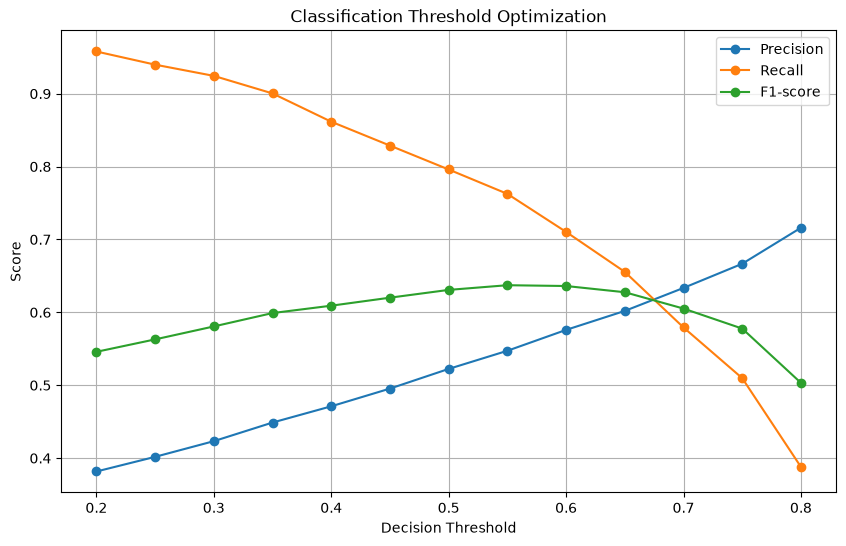

In [9]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision",
    marker="o"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall",
    marker="o"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1-score",
    marker="o"
)

plt.title("Classification Threshold Optimization")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()

:-Select the threshold

In [10]:
best_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_threshold = float(best_row["Threshold"])

print("Selected threshold:", best_threshold)
print("CV F1-score:", round(best_row["F1"], 4))
print("CV Recall:", round(best_row["Recall"], 4))

Selected threshold: 0.55
CV F1-score: 0.6372
CV Recall: 0.7625


Evaluate the optimized model

-:Generate predictions

In [11]:
test_probabilities = tuned_pipeline.predict_proba(
    X_test
)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["Retained", "Churned"],
        zero_division=0
    )
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, test_probabilities), 4)
)

              precision    recall  f1-score   support

    Retained       0.89      0.75      0.82      1035
     Churned       0.52      0.75      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.75      0.76      1409

ROC-AUC: 0.8402


-: Confusion matrix

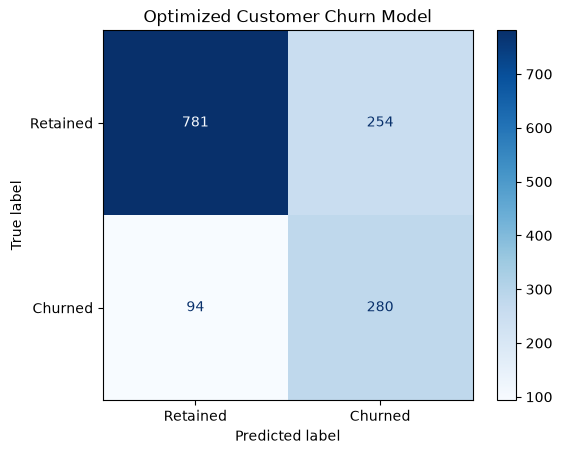

In [12]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Retained", "Churned"],
    cmap="Blues"
)

plt.title("Optimized Customer Churn Model")
plt.show()

Explainable AI using SHAP
This is an important feature for making your project stand out in interviews.

SHAP (SHapley Additive exPlanations) helps explain how individual features contribute to a model's predictions.

For example, the model may associate a customer's month-to-month contract and short tenure with a higher predicted churn probability.

SHAP describes the model's behavior; it does not prove that these features cause churn.

Prepare data for SHAP

-: Replace your existing SHAP code

In [13]:
import pandas as pd
import numpy as np
import shap

X_train_shap = X_train.copy()
X_test_shap = X_test.copy()

categorical_columns = X_train.select_dtypes(
    include=["object", "category"]
).columns

category_mappings = {}

for col in categorical_columns:

    categories = pd.Categorical(X_train[col]).categories

    category_mappings[col] = categories

    X_train_shap[col] = pd.Categorical(
        X_train[col],
        categories=categories
    ).codes

    X_test_shap[col] = pd.Categorical(
        X_test[col],
        categories=categories
    ).codes

print("SHAP data prepared successfully!")

SHAP data prepared successfully!


C:\Users\yashr\AppData\Local\Temp\ipykernel_7612\155270187.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


-: Create a prediction function

In [14]:
feature_columns = X_train.columns.tolist()

def predict_churn_probability(data):

    data_df = pd.DataFrame(
        data,
        columns=feature_columns
    )

    for col, categories in category_mappings.items():

        codes = np.rint(
            data_df[col].to_numpy(dtype=float)
        ).astype(int)

        data_df[col] = pd.Categorical.from_codes(
            codes,
            categories=categories
        ).astype(object)

    return tuned_pipeline.predict_proba(
        data_df
    )[:, 1]

print("Prediction function created!")

Prediction function created!


-: Calculate SHAP values again

In [15]:
background = X_train_shap.sample(
    n=30,
    random_state=42
)

explain_data = X_test_shap.head(10).copy()

explainer = shap.Explainer(
    predict_churn_probability,
    shap.maskers.Independent(background),
    algorithm="permutation"
)

shap_values = explainer(
    explain_data,
    max_evals=2 * X_train_shap.shape[1] + 1
)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


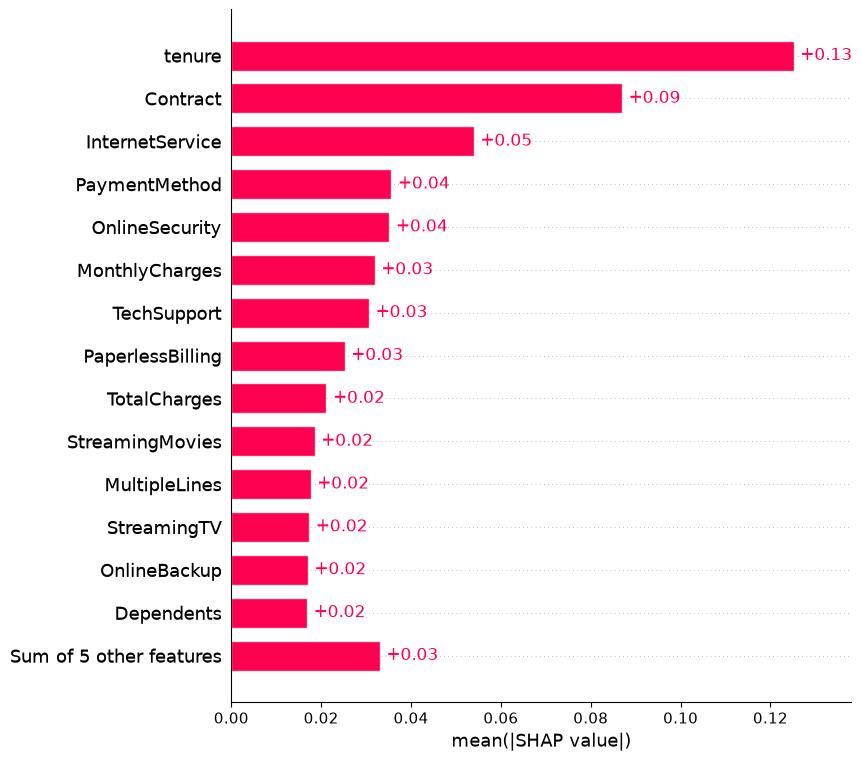

In [34]:
shap.plots.bar(shap_values, max_display=15)

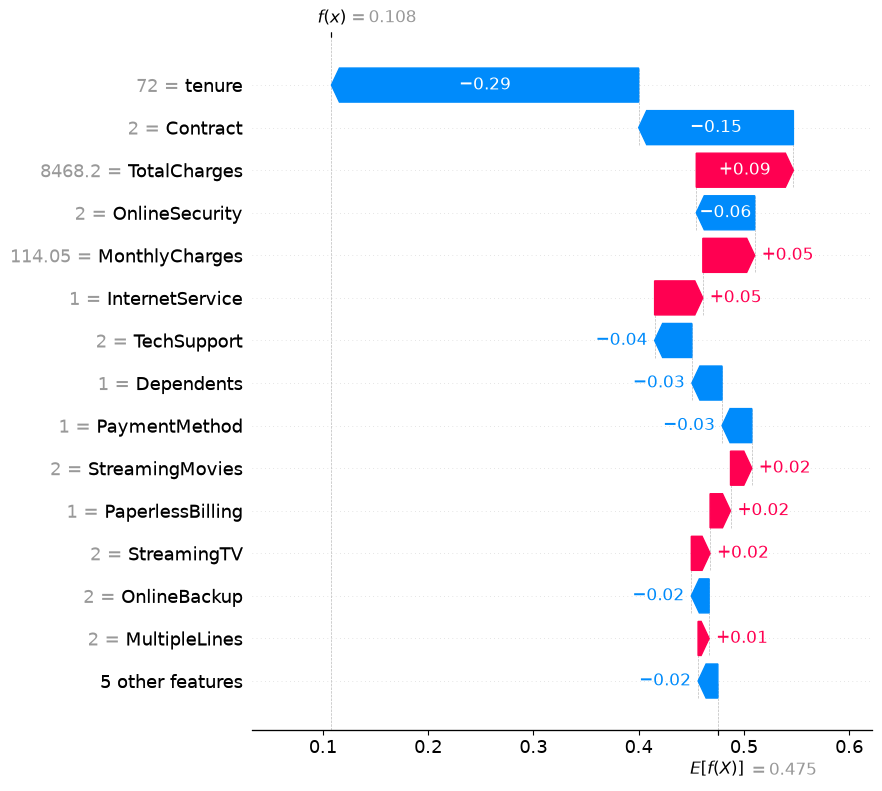

In [16]:
shap.plots.waterfall(shap_values[0], max_display=15)

Predict customer churn probability

-: Generate customer risk scores

In [17]:
customer_predictions = X_test.copy()

customer_predictions["ActualChurn"] = y_test.to_numpy()

customer_predictions["ChurnProbability"] = (
    test_probabilities
)

customer_predictions["PredictedChurn"] = (
    test_predictions
)

display(
    customer_predictions[
        [
            "tenure",
            "Contract",
            "MonthlyCharges",
            "ChurnProbability",
            "PredictedChurn"
        ]
    ].head(10)
)

,tenure,Contract,MonthlyCharges,ChurnProbability,PredictedChurn
0,72,Two year,114.05,0.108104,0
1,8,Month-to-month,100.15,0.854875,1
2,41,One year,78.35,0.166639,0
3,18,Month-to-month,78.20,0.646908,1
4,72,Two year,82.65,0.069558,0
5,21,Month-to-month,99.85,0.808150,1
6,21,Month-to-month,99.15,0.698570,1
7,19,Month-to-month,24.10,0.295174,0
8,61,Two year,19.75,0.015205,0
9,17,Month-to-month,45.05,0.658110,1


-: Create risk categories

In [18]:
customer_predictions["RiskCategory"] = pd.cut(
    customer_predictions["ChurnProbability"],
    bins=[-0.001, 0.30, 0.60, 1.0],
    labels=["Low", "Medium", "High"]
)

display(
    customer_predictions[
        [
            "ChurnProbability",
            "PredictedChurn",
            "RiskCategory"
        ]
    ].head(10)
)

,ChurnProbability,PredictedChurn,RiskCategory
0,0.108104,0,Low
1,0.854875,1,High
2,0.166639,0,Low
3,0.646908,1,High
4,0.069558,0,Low
5,0.808150,1,High
6,0.698570,1,High
7,0.295174,0,Low
8,0.015205,0,Low
9,0.658110,1,High


Save your optimized model, threshold, and reports

-:Save model and threshold

In [19]:
import json

models_dir = project / "models"
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    tuned_pipeline,
    models_dir / "optimized_churn_model.pkl"
)

with open(
    models_dir / "prediction_settings.json",
    "w"
) as f:
    json.dump(
        {
            "threshold": best_threshold,
            "model": classifier_name
        },
        f,
        indent=4
    )

print("Optimized model and threshold saved!")

Optimized model and threshold saved!


-: Save reports

In [20]:
report_dir = project / "Report"
report_dir.mkdir(parents=True, exist_ok=True)

threshold_df.to_csv(
    report_dir / "threshold_comparison.csv",
    index=False
)

customer_predictions.to_csv(
    report_dir / "customer_churn_predictions.csv",
    index=False
)

print("Reports saved successfully!")

Reports saved successfully!


-: Verify all saved files

In [21]:
files_to_check = [
    models_dir / "optimized_churn_model.pkl",
    models_dir / "prediction_settings.json",
    report_dir / "threshold_comparison.csv",
    report_dir / "customer_churn_predictions.csv"
]

for file in files_to_check:
    print(file.name, ":", file.exists())

optimized_churn_model.pkl : True
prediction_settings.json : True
threshold_comparison.csv : True
customer_churn_predictions.csv : True
